# Plan de abastecimiento — Los Finos ERP

## A. Objetivo y alcance

Convertir el pronóstico XGBoost de **productos vendidos** (29/10–11/11/2026) en **necesidades de insumos** y una **propuesta de abastecimiento**.

- Datos **sintéticos** (lote `LF-DEMANDA-V1`): demuestra el método, no acredita resultados sobre operación real.
- Las recepciones son **hipotéticas**: no cambian existencias ni son compras aprobadas. No se crean solicitudes ni órdenes.
- **Stock inicial:** `LFSim_Insumo.StockFinal` al cierre del 28/10 (no `Insumo.StockActual`, que pudo cambiar después). La integración operativa usará existencias vigentes.
- **Recetas:** fotografía `LFSim_Receta` del lote. **StockMinimo** (catálogo actual) es un saldo objetivo *provisional*.
- Plazo de entrega cero (compra y recepción el mismo día, antes del consumo); sin mínimos comerciales, capacidad, vencimientos ni mermas.
- **Órdenes pendientes no incorporadas** porque aún no están implementadas; eso no verifica que no existan compromisos.
- El proveedor es una sugerencia del escenario simulado, no una selección ni una comparación de cotizaciones.
- Solo lectura en SQL Server.

## B. Entradas y controles

In [1]:
import sys
from pathlib import Path

_base = Path.cwd().resolve()
_cands = [b / r for b in (_base, *_base.parents) for r in ("src", "python/src")]
_src = next(x for x in _cands if (x / "losfinos_demanda").is_dir())
if str(_src) not in sys.path:
    sys.path.insert(0, str(_src))
RAIZ_PY = _src.parent
ENTRADA = RAIZ_PY / "artifacts" / "demanda"
SALIDA = RAIZ_PY / "artifacts" / "abastecimiento"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from losfinos_demanda import config, graficos, abastecimiento as ab

graficos.estilo()
pd.set_option("display.max_columns", 30, "display.width", 220, "display.max_rows", 80)

pron, meta = ab.cargar_pronostico(ENTRADA)
ab.validar_pronostico(pron, meta)
print(f"Pronóstico: {len(pron)} filas | {pron['Fecha'].min().date()} → {pron['Fecha'].max().date()} | "
      f"corte {meta['fecha_corte']} | lote {meta['lote']} | modelo xgboost {meta['versiones']['xgboost']}")

Pronóstico: 140 filas | 2026-10-29 → 2026-11-11 | corte 2026-10-28 | lote LF-DEMANDA-V1 | modelo xgboost 3.2.0


In [2]:
engine = config.crear_engine()
config.probar_conexion(engine)
cat = ab.cargar_catalogo(engine)
lote, recetas, insumos = cat["lote"].iloc[0], cat["recetas"], cat["insumos"]
ANCLAJE = lote["FechaInicio"]
FECHAS = list(pd.date_range(pron["Fecha"].min(), pron["Fecha"].max()))
print(f"Lote {lote['Codigo']}: {lote['FechaInicio'].date()} → {lote['FechaFin'].date()} | anclaje de ciclos: {ANCLAJE.date()}")

ab.validar_recetas_insumos(pron, recetas, insumos)
print(f"Controles de entrada OK: {pron['ProductoID'].nunique()} productos con receta, {len(recetas)} componentes sin duplicados, "
      f"cantidades > 0, {len(insumos)} insumos válidos con unidad y política conocidas.")
display(insumos[["InsumoID", "NombreInsumo", "Unidad", "StockFinal", "StockMinimo", "EsPerecible", "Politica", "CostoFijo", "ProveedorPropuesto"]])

Lote LF-DEMANDA-V1: 2026-04-29 → 2026-10-28 | anclaje de ciclos: 2026-04-29
Controles de entrada OK: 10 productos con receta, 41 componentes sin duplicados, cantidades > 0, 16 insumos válidos con unidad y política conocidas.


,InsumoID,NombreInsumo,Unidad,StockFinal,StockMinimo,EsPerecible,Politica,CostoFijo,ProveedorPropuesto
0,1,Pollo Entero Fresco Beneficiado,Kilogramo (Kg),2.592,15.0,True,DIARIO,8.50,Distribuidora Avícola San Fernando S.A.
1,2,Lomo Fino de Res,Kilogramo (Kg),0.588,5.0,True,MAR-JUE-SAB,32.00,Carnes del Norte E.I.R.L.
2,3,Carne para Guiso / Saltado,Kilogramo (Kg),0.180,8.0,True,MAR-JUE-SAB,24.00,Carnes del Norte E.I.R.L.
3,4,Papas Canchán Peladas y Cortadas,Kilogramo (Kg),2.163,20.0,True,DIARIO,2.80,Comercializadora de Abarrotes Huacho S.A.C.
4,5,Arroz Superior Extra,Kilogramo (Kg),5.942,50.0,False,CADA-14-DIAS,3.80,Comercializadora de Abarrotes Huacho S.A.C.
5,6,Aceite Vegetal Industrial,Litro (L),2.410,15.0,False,CADA-14-DIAS,7.20,Comercializadora de Abarrotes Huacho S.A.C.
6,7,Cebolla Roja,Kilogramo (Kg),0.468,10.0,True,DIARIO,2.50,Comercializadora de Abarrotes Huacho S.A.C.
7,8,Tomate Italiano,Kilogramo (Kg),0.347,8.0,True,DIARIO,3.00,Comercializadora de Abarrotes Huacho S.A.C.
8,9,Sillao / Salsa de Soya Tin Tan,Botella / Frasco,0.710,4.0,False,CADA-14-DIAS,14.50,Comercializadora de Abarrotes Huacho S.A.C.
9,10,Maíz Morado Seco,Kilogramo (Kg),0.625,5.0,False,CADA-14-DIAS,5.50,Comercializadora de Abarrotes Huacho S.A.C.


## C. Necesidades brutas

`Necesidad = UnidadesPronosticadas × CantidadUtilizada`, sumada por fecha e insumo. No se redondean los platos antes de multiplicar.

In [3]:
detalle, diarias = ab.calcular_necesidades(pron, recetas, insumos)
chk = detalle.groupby(["Fecha", "InsumoID"])["Necesidad"].sum().reset_index().merge(diarias, on=["Fecha", "InsumoID"])
assert np.allclose(chk["Necesidad_x"], chk["Necesidad_y"]) and len(chk) == len(diarias)
print("Necesidad agregada = suma del detalle por producto: OK")

# Ejemplo trazable plato -> ingredientes (primer día, plato con mayor pronóstico)
dia = pron["Fecha"].min()
plato = pron[pron["Fecha"] == dia].nlargest(1, "UnidadesPronosticadas").iloc[0]
print(f"{dia.date()} · {plato['NombreProducto']}: {plato['UnidadesPronosticadas']:.3f} unidades pronosticadas")
display(detalle[(detalle["Fecha"] == dia) & (detalle["ProductoID"] == plato["ProductoID"])]
        [["NombreInsumo", "Unidad", "UnidadesPronosticadas", "CantidadUtilizada", "Necesidad"]].round({"UnidadesPronosticadas": 3, "CantidadUtilizada": 4, "Necesidad": 4}))

Necesidad agregada = suma del detalle por producto: OK
2026-10-29 · Inca Kola 500ml: 13.671 unidades pronosticadas


,NombreInsumo,Unidad,UnidadesPronosticadas,CantidadUtilizada,Necesidad
40,Inca Kola 500ml - SIM,Unidad (Und),13.671,1.0,13.6707


NombreInsumo,Aceite Vegetal Industrial,Arroz Superior Extra,Azúcar - SIM,Carne para Guiso / Saltado,Cebolla Roja,Huevos de Gallina Frescos,Inca Kola 500ml - SIM,Limón - SIM,Lomo Fino de Res,Maíz Morado Seco,Papas Canchán Peladas y Cortadas,Pollo Entero Fresco Beneficiado,Sillao / Salsa de Soya Tin Tan,Tallarín seco - SIM,Tomate Italiano,Zanahoria - SIM
Fecha,,,,,,,,,,,,,,,,
2026-10-29,2.31,5.60,0.37,0.74,1.79,20.05,13.67,0.11,2.14,0.56,8.06,9.77,0.64,0.62,1.30,0.00
2026-10-30,2.64,6.64,0.58,0.70,2.09,22.21,13.87,0.17,2.61,0.87,9.70,11.49,0.52,0.59,1.50,0.41
2026-10-31,3.23,7.90,0.40,0.72,2.40,26.22,19.51,0.12,3.41,0.60,12.00,13.62,0.71,0.60,1.87,0.00
2026-11-01,3.02,7.07,0.44,0.71,2.17,25.53,20.28,0.13,3.03,0.66,11.03,12.88,0.59,0.60,1.69,0.19
2026-11-02,1.87,4.90,0.32,0.50,1.50,15.98,12.07,0.10,1.89,0.48,6.51,8.09,0.52,0.42,1.08,0.00
2026-11-03,1.92,4.70,0.32,0.66,1.60,15.86,12.42,0.10,1.96,0.48,7.08,8.01,0.39,0.55,1.18,0.25
2026-11-04,2.10,5.18,0.44,0.82,1.75,17.69,12.50,0.13,2.02,0.66,7.18,8.85,0.59,0.69,1.28,0.00
2026-11-05,2.29,5.78,0.38,0.71,1.87,19.88,13.78,0.11,2.32,0.57,8.38,9.68,0.48,0.59,1.37,0.31
2026-11-06,2.67,6.73,0.38,0.90,2.31,22.02,14.50,0.11,2.87,0.57,9.20,11.11,0.72,0.75,1.71,0.00


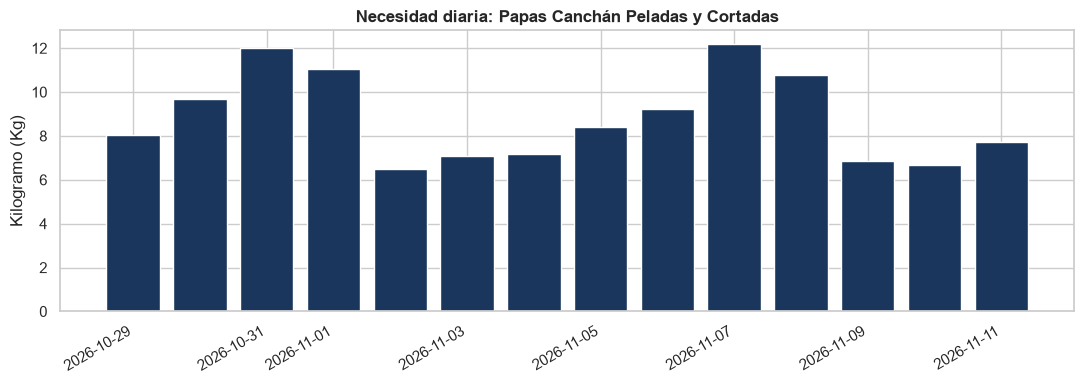

In [4]:
ancho = diarias.pivot(index="Fecha", columns="NombreInsumo", values="Necesidad").round(2)
display(ancho)
INSUMO_NECESIDAD = 4   # cambie el InsumoID para ver otro insumo
n = diarias[diarias["InsumoID"] == INSUMO_NECESIDAD].set_index("Fecha")
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(n.index, n["Necesidad"], color="#1b365d")
ax.set(title=f"Necesidad diaria: {n['NombreInsumo'].iloc[0]}", ylabel=n["Unidad"].iloc[0])
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## D. Planificación secuencial

En cada reposición programada: `Compra = máx(0, consumo de cobertura + StockMinimo − saldo)`, con cobertura hasta el día anterior a la siguiente reposición (truncada al horizonte). Si antes de la siguiente fecha programada se prevé un faltante, se propone una reposición **«Urgente propuesta»** que cubre solo el consumo hasta esa fecha. Solo se redondea la compra: entero superior para Unidad y Botella/Frasco, múltiplo superior de 0,001 para Kg y Litro. El saldo se arrastra (saldo final = saldo inicial + recepción − consumo).

In [5]:
prop, saldos = ab.planificar(diarias, insumos, FECHAS, ANCLAJE)
ver = ab.verificar_plan(prop, saldos, diarias, detalle, insumos, ANCLAJE)
print(ver)
print(f"Compras propuestas: {len(prop)} ({(prop['TipoPropuesta'] == 'Urgente propuesta').sum()} urgentes) · "
      f"{prop['InsumoID'].nunique()} insumos de {len(insumos)}")

{'necesidad_agregada_igual_detalle': True, 'balance_por_paso': True, 'sin_doble_descuento': True, 'sin_saldos_negativos': True, 'redondeo_correcto': True, 'compras_en_fechas_programadas_o_urgentes': True, 'cobertura_truncada_coherente': True, 'cobertura_truncada_marcada': 8}
Compras propuestas: 113 (8 urgentes) · 16 insumos de 16


### Calendario de compras sugeridas (hipotéticas)

In [6]:
display(prop[["FechaRecepcionPropuesta", "InsumoID", "NombreInsumo", "Unidad", "Politica", "TipoPropuesta", "CoberturaHasta",
              "CoberturaTruncada", "SaldoAntes", "NecesidadCobertura", "StockObjetivo", "CantidadSugerida",
              "CostoUnitarioReferencial", "ImporteEstimado", "ProveedorID", "ProveedorPropuesto"]].round({"SaldoAntes": 3, "NecesidadCobertura": 3, "StockObjetivo": 3, "CantidadSugerida": 3, "CostoUnitarioReferencial": 2, "ImporteEstimado": 2}))
sin_compra = insumos[~insumos["InsumoID"].isin(prop["InsumoID"])]
print("Insumos sin compra sugerida:", sin_compra[["InsumoID", "NombreInsumo"]].values.tolist())
trunc = prop[prop["CoberturaTruncada"]]
print(f"AVISO: {len(trunc)} compras tienen cobertura truncada por el horizonte de {len(FECHAS)} días: "
      "cubren hasta el 11/11 y no el ciclo completo de su política.")

,FechaRecepcionPropuesta,InsumoID,NombreInsumo,Unidad,Politica,TipoPropuesta,CoberturaHasta,CoberturaTruncada,SaldoAntes,NecesidadCobertura,StockObjetivo,CantidadSugerida,CostoUnitarioReferencial,ImporteEstimado,ProveedorID,ProveedorPropuesto
0,2026-10-29,1,Pollo Entero Fresco Beneficiado,Kilogramo (Kg),DIARIO,Programada,2026-10-29,False,2.592,9.766,15.0,22.174,8.5,188.48,1,Distribuidora Avícola San Fernando S.A.
1,2026-10-29,2,Lomo Fino de Res,Kilogramo (Kg),MAR-JUE-SAB,Programada,2026-10-30,False,0.588,4.749,5.0,9.162,32.0,293.18,2,Carnes del Norte E.I.R.L.
2,2026-10-29,3,Carne para Guiso / Saltado,Kilogramo (Kg),MAR-JUE-SAB,Programada,2026-10-30,False,0.180,1.443,8.0,9.264,24.0,222.34,2,Carnes del Norte E.I.R.L.
3,2026-10-29,4,Papas Canchán Peladas y Cortadas,Kilogramo (Kg),DIARIO,Programada,2026-10-29,False,2.163,8.058,20.0,25.895,2.8,72.51,3,Comercializadora de Abarrotes Huacho S.A.C.
4,2026-10-29,7,Cebolla Roja,Kilogramo (Kg),DIARIO,Programada,2026-10-29,False,0.468,1.788,10.0,11.320,2.5,28.30,3,Comercializadora de Abarrotes Huacho S.A.C.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,2026-11-11,12,Tallarín seco - SIM,Kilogramo (Kg),CADA-14-DIAS,Programada,2026-11-11,True,0.001,0.581,3.0,3.580,5.5,19.69,3,Comercializadora de Abarrotes Huacho S.A.C.
109,2026-11-11,13,Zanahoria - SIM,Kilogramo (Kg),DIARIO,Programada,2026-11-11,False,2.000,0.257,2.0,0.257,2.5,0.64,3,Comercializadora de Abarrotes Huacho S.A.C.
110,2026-11-11,14,Azúcar - SIM,Kilogramo (Kg),CADA-14-DIAS,Programada,2026-11-11,True,0.001,0.396,3.0,3.396,4.0,13.58,3,Comercializadora de Abarrotes Huacho S.A.C.
111,2026-11-11,15,Limón - SIM,Kilogramo (Kg),DIARIO,Programada,2026-11-11,False,1.001,0.119,1.0,0.119,4.5,0.54,3,Comercializadora de Abarrotes Huacho S.A.C.


Insumos sin compra sugerida: []
AVISO: 8 compras tienen cobertura truncada por el horizonte de 14 días: cubren hasta el 11/11 y no el ciclo completo de su política.


### Advertencia sobre perecibles

In [7]:
adv = ab.advertencias_perecibles(insumos, diarias, len(FECHAS))
print(f"Perecibles cuyo stock objetivo (StockMinimo provisional) supera {ab.UMBRAL_PERECIBLE_DIAS:g} días de consumo previsto: "
      "no es una política optimizada.")
display(adv.round({"StockMinimo": 3, "ConsumoDiarioMedio": 3, "DiasCoberturaObjetivo": 2}))

Perecibles cuyo stock objetivo (StockMinimo provisional) supera 2 días de consumo previsto: no es una política optimizada.


,InsumoID,NombreInsumo,Unidad,StockMinimo,ConsumoDiarioMedio,DiasCoberturaObjetivo
0,2,Lomo Fino de Res,Kilogramo (Kg),5.0,2.463,2.03
1,3,Carne para Guiso / Saltado,Kilogramo (Kg),8.0,0.709,11.29
2,4,Papas Canchán Peladas y Cortadas,Kilogramo (Kg),20.0,8.813,2.27
3,7,Cebolla Roja,Kilogramo (Kg),10.0,1.919,5.21
4,8,Tomate Italiano,Kilogramo (Kg),8.0,1.435,5.58
5,11,Huevos de Gallina Frescos,Unidad (Und),60.0,20.484,2.93
6,13,Zanahoria - SIM,Kilogramo (Kg),2.0,0.134,14.92
7,15,Limón - SIM,Kilogramo (Kg),1.0,0.119,8.39


### Evolución diaria del saldo proyectado

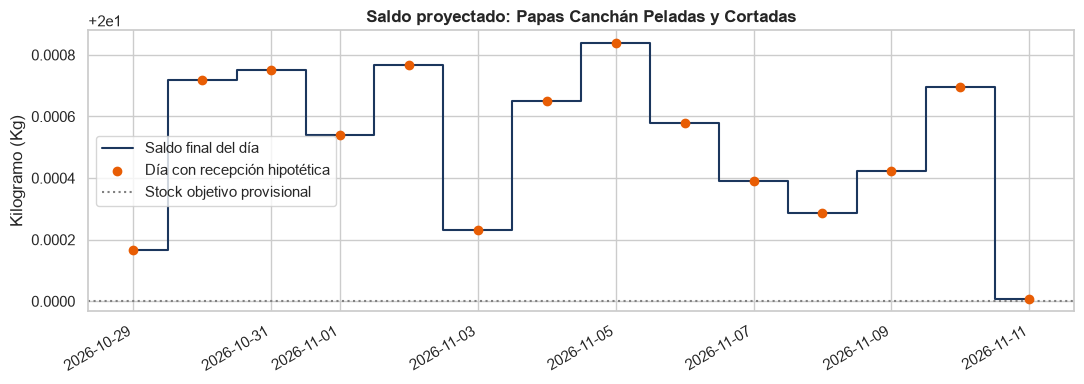

,SaldoInicial,RecepcionPropuesta,Consumo,SaldoFinal
Fecha,,,,
2026-10-29,2.163,25.895,8.058,20.000
2026-10-30,20.000,9.699,9.698,20.001
2026-10-31,20.001,12.004,12.004,20.001
2026-11-01,20.001,11.034,11.034,20.001
2026-11-02,20.001,6.506,6.506,20.001
2026-11-03,20.001,7.082,7.083,20.000
2026-11-04,20.000,7.179,7.179,20.001
2026-11-05,20.001,8.383,8.383,20.001
2026-11-06,20.001,9.204,9.204,20.001


In [8]:
INSUMO_GRAFICO = 4   # cambie el InsumoID para ver otro insumo
s = saldos[saldos["InsumoID"] == INSUMO_GRAFICO].set_index("Fecha")
nombre, unidad = s["NombreInsumo"].iloc[0], s["Unidad"].iloc[0]
fig, ax = plt.subplots(figsize=(11, 4))
ax.step(s.index, s["SaldoFinal"], where="mid", color="#1b365d", label="Saldo final del día")
compras = s[s["RecepcionPropuesta"] > 0]
ax.scatter(compras.index, compras["SaldoFinal"], color="#e85d04", zorder=3, label="Día con recepción hipotética")
ax.axhline(insumos.set_index("InsumoID").loc[INSUMO_GRAFICO, "StockMinimo"], color="grey", linestyle=":", label="Stock objetivo provisional")
ax.set(title=f"Saldo proyectado: {nombre}", ylabel=unidad); ax.legend(); fig.autofmt_xdate(); fig.tight_layout(); plt.show()
display(s[["SaldoInicial", "RecepcionPropuesta", "Consumo", "SaldoFinal"]].round(3))

### Resumen por proveedor propuesto

Las cantidades se mantienen **separadas por insumo y unidad** (no se suman Kg, litros y unidades). Los importes sí se suman, pero son **referenciales: no son cotizaciones y no incluyen condiciones del proveedor**.

In [9]:
res = ab.resumen_proveedor(prop)
display(res.round({"CantidadSugerida": 3, "ImporteEstimado": 2}))
display(res.groupby(["ProveedorID", "ProveedorPropuesto"])[["ImporteEstimado"]].sum().round(2).rename(columns={"ImporteEstimado": "ImporteEstimado (referencial, S/)"}))
print(f"Importe estimado total: S/ {prop['ImporteEstimado'].sum():,.2f} (referencial; no es cotización)")

,ProveedorID,ProveedorPropuesto,InsumoID,NombreInsumo,Unidad,Compras,CantidadSugerida,ImporteEstimado
0,1,Distribuidora Avícola San Fernando S.A.,1,Pollo Entero Fresco Beneficiado,Kilogramo (Kg),14,157.138,1335.70
1,2,Carnes del Norte E.I.R.L.,2,Lomo Fino de Res,Kilogramo (Kg),6,38.899,1244.77
2,2,Carnes del Norte E.I.R.L.,3,Carne para Guiso / Saltado,Kilogramo (Kg),6,17.744,425.86
3,3,Comercializadora de Abarrotes Huacho S.A.C.,4,Papas Canchán Peladas y Cortadas,Kilogramo (Kg),14,141.223,395.44
4,3,Comercializadora de Abarrotes Huacho S.A.C.,5,Arroz Superior Extra,Kilogramo (Kg),2,128.045,486.57
5,3,Comercializadora de Abarrotes Huacho S.A.C.,6,Aceite Vegetal Industrial,Litro (L),2,46.778,336.80
6,3,Comercializadora de Abarrotes Huacho S.A.C.,7,Cebolla Roja,Kilogramo (Kg),14,36.405,91.00
7,3,Comercializadora de Abarrotes Huacho S.A.C.,8,Tomate Italiano,Kilogramo (Kg),14,27.740,83.22
8,3,Comercializadora de Abarrotes Huacho S.A.C.,9,Sillao / Salsa de Soya Tin Tan,Botella / Frasco,2,12.000,174.00
9,3,Comercializadora de Abarrotes Huacho S.A.C.,10,Maíz Morado Seco,Kilogramo (Kg),2,12.722,69.97


,,"ImporteEstimado (referencial, S/)"
ProveedorID,ProveedorPropuesto,
1,Distribuidora Avícola San Fernando S.A.,1335.70
2,Carnes del Norte E.I.R.L.,1670.63
3,Comercializadora de Abarrotes Huacho S.A.C.,1937.30
4,Distribuidora de Bebidas y Licores Don Pepe,582.40


Importe estimado total: S/ 5,526.03 (referencial; no es cotización)


## E. Validación

In [10]:
# Ejemplo pequeño con resultado calculado manualmente (ver docstring de verificar_ejemplo_manual)
display(ab.verificar_calendario())  # fechas conocidas escritas a mano
print('Calendario y cobertura (DIARIO 11/11, MAR-JUE-SAB 10/11, ciclo truncado): OK')
display(ab.verificar_ejemplo_manual())

# Error claro ante una receta faltante
sin_receta = recetas[recetas["ProductoID"] != 3]
try:
    ab.validar_recetas_insumos(pron, sin_receta, insumos)
except ab.AbastecimientoError as e:
    print("Error esperado:", e)
else:
    raise AssertionError("Debía fallar por receta faltante")

# Unidad no contemplada
try:
    ab.redondear_compra(1.0, "Caja")
except ab.AbastecimientoError as e:
    print("Error esperado:", e)

# Sin saldos negativos ni doble descuento: el saldo inicial del plan es exactamente el stock del snapshot
assert (saldos["SaldoFinal"] >= 0).all()
print("Validaciones OK. Todo el balance:", ver)

,Fecha,DiaSemana,EsMarJueSab
0,2026-10-27,martes,True
1,2026-10-28,miércoles,False
2,2026-10-29,jueves,True
3,2026-10-30,viernes,False
4,2026-10-31,sábado,True
5,2026-11-01,domingo,False


Calendario y cobertura (DIARIO 11/11, MAR-JUE-SAB 10/11, ciclo truncado): OK


,caso,compras,esperado
0,A,2,"4,5 y 1,5"
1,B,1,"Urgente 3,5"
2,C,1,3 unidades


Error esperado: Productos pronosticados sin receta: [3]. No se calculan necesidades.
Error esperado: Unidad sin regla de redondeo: 'Caja'. Configúrela explícitamente.
Validaciones OK. Todo el balance: {'necesidad_agregada_igual_detalle': True, 'balance_por_paso': True, 'sin_doble_descuento': True, 'sin_saldos_negativos': True, 'redondeo_correcto': True, 'compras_en_fechas_programadas_o_urgentes': True, 'cobertura_truncada_coherente': True, 'cobertura_truncada_marcada': 8}


## F. Guardado de resultados

In [11]:
metadata = ab.construir_metadata(meta, lote, FECHAS, ANCLAJE, insumos)
metadata["resumen"] = {"compras": int(len(prop)), "urgentes": int((prop["TipoPropuesta"] == "Urgente propuesta").sum()),
                       "insumos_con_compra": sorted(int(i) for i in prop["InsumoID"].unique()),
                       "importe_estimado_total": round(float(prop["ImporteEstimado"].sum()), 2),
                       "controles": {k: (v if not isinstance(v, (np.bool_, np.integer)) else v.item()) for k, v in ver.items()}}
ab.guardar_resultados(SALIDA, detalle, diarias, prop, saldos, metadata)
print(sorted(p.name for p in SALIDA.iterdir()))

['metadata_abastecimiento.json', 'necesidades_detalle.csv', 'necesidades_diarias.csv', 'propuesta_abastecimiento.csv', 'saldos_proyectados.csv']


## G. Conclusiones y limitaciones

- La propuesta es una **demostración con datos sintéticos** y recepciones **hipotéticas**; no son compras aprobadas.
- El stock inicial es el del snapshot del lote; con existencias vigentes el resultado cambiaría.
- `StockMinimo` es provisional; en perecibles puede implicar cobertura elevada.
- Sin órdenes pendientes, plazos de entrega, mínimos comerciales, capacidad, vencimientos ni mermas.
- Las compras con cobertura truncada solo cubren hasta el fin del horizonte.
- Los importes son referenciales, no cotizaciones.
- Siguiente paso: integrar existencias vigentes y órdenes pendientes, y definir la aprobación humana de solicitudes.